# Module 6 — Randomized email experiment

This notebook reads verified exports; the complete calculation is in `scripts/run_hillstrom.py`, `scripts/hillstrom_methods.py` and `sql/06_hillstrom.sql`. Monetary values are USD. This is a separate retailer experiment, not the grocery campaign population.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT=Path.cwd()
DATA=ROOT/'exports/hillstrom'
def load(name):
    return pd.read_csv(DATA/f'{name}.csv')
source=json.loads((ROOT/'docs/hillstrom_source.json').read_text(encoding='utf-8'))
print('Customers:', source['rows'], '| CSV SHA-256:', source['csv_sha256'])
display(load('hillstrom_arm_summary'))
display(load('hillstrom_srm'))
display(load('hillstrom_balance').sort_values('standardized_mean_difference',key=abs,ascending=False).head())

Customers: 64000 | CSV SHA-256: 00a6a868e05a9ffe7382da51629f6d6dce88c5acfc945e79d314ebc78fd3a2c0


,segment,customers,visitors,buyers,total_spend,visit_rate,conversion_rate,spend_per_assigned_customer
0,Mens E-Mail,21307,3894.0,267.0,30311.69,0.182757,0.012531,1.422617
1,No E-Mail,21306,2262.0,122.0,13908.33,0.106167,0.005726,0.652789
2,Womens E-Mail,21387,3238.0,189.0,23038.11,0.151400,0.008837,1.077202


,expected_assignment_probability,arms,customers,chi_square,degrees_of_freedom,p_value,warning_threshold,sample_ratio_warning
0,0.333333,3,64000,0.202531,2,0.903693,0.01,False


,arm,baseline_feature,treatment_mean,control_mean,standardized_mean_difference
5,Mens E-Mail,zip_code=Rural,0.152204,0.147329,0.013659
6,Mens E-Mail,zip_code=Surburban,0.445910,0.451751,-0.011743
10,Mens E-Mail,channel=Web,0.445394,0.439923,0.011014
14,Womens E-Mail,mens,0.548932,0.553224,-0.008631
20,Womens E-Mail,channel=Phone,0.442044,0.437764,0.008623


## 1. Compare outcomes per randomized customer

Keep zeros. Compare each version with no email; then compare the two versions directly. Rates use 0–1 units; 0.01 is one percentage point. All intervals are pointwise 95% bootstrap intervals, with 2,000 resamples and seed 42. Welch p values use Holm families of six primary and three direct contrasts; intervals are not multiplicity-adjusted.

,arm,reference_arm,metric,n_treatment,n_control,status,treatment_mean,control_mean,estimate,ci_low,ci_high,p_value,p_holm,reject_zero_holm_05
0,Mens E-Mail,No E-Mail,visit,21307,21306,estimated,0.182757,0.106167,0.076590,0.070158,0.083348,1.364451e-112,8.186707e-112,True
1,Mens E-Mail,No E-Mail,conversion,21307,21306,estimated,0.012531,0.005726,0.006805,0.004928,0.008637,1.501816e-13,6.007263e-13,True
2,Mens E-Mail,No E-Mail,spend,21307,21306,estimated,1.422617,0.652789,0.769827,0.484852,1.040796,1.163815e-07,3.491445e-07,True
3,Womens E-Mail,No E-Mail,visit,21387,21306,estimated,0.151400,0.106167,0.045233,0.039008,0.051937,2.432448e-44,1.216224e-43,True
4,Womens E-Mail,No E-Mail,conversion,21387,21306,estimated,0.008837,0.005726,0.003111,0.001517,0.004749,1.560284e-04,3.120568e-04,True
5,Womens E-Mail,No E-Mail,spend,21387,21306,estimated,1.077202,0.652789,0.424412,0.179975,0.699180,1.129397e-03,1.129397e-03,True


,arm,reference_arm,metric,n_treatment,n_control,status,treatment_mean,control_mean,estimate,ci_low,ci_high,p_value,p_holm,reject_zero_holm_05
0,Mens E-Mail,Womens E-Mail,visit,21307,21387,estimated,0.182757,0.151400,0.031356,0.023960,0.037975,3.724744e-18,1.117423e-17,True
1,Mens E-Mail,Womens E-Mail,conversion,21307,21387,estimated,0.012531,0.008837,0.003694,0.001726,0.005615,2.059731e-04,4.119461e-04,True
2,Mens E-Mail,Womens E-Mail,spend,21307,21387,estimated,1.422617,1.077202,0.345415,0.030434,0.653121,3.046865e-02,3.046865e-02,True


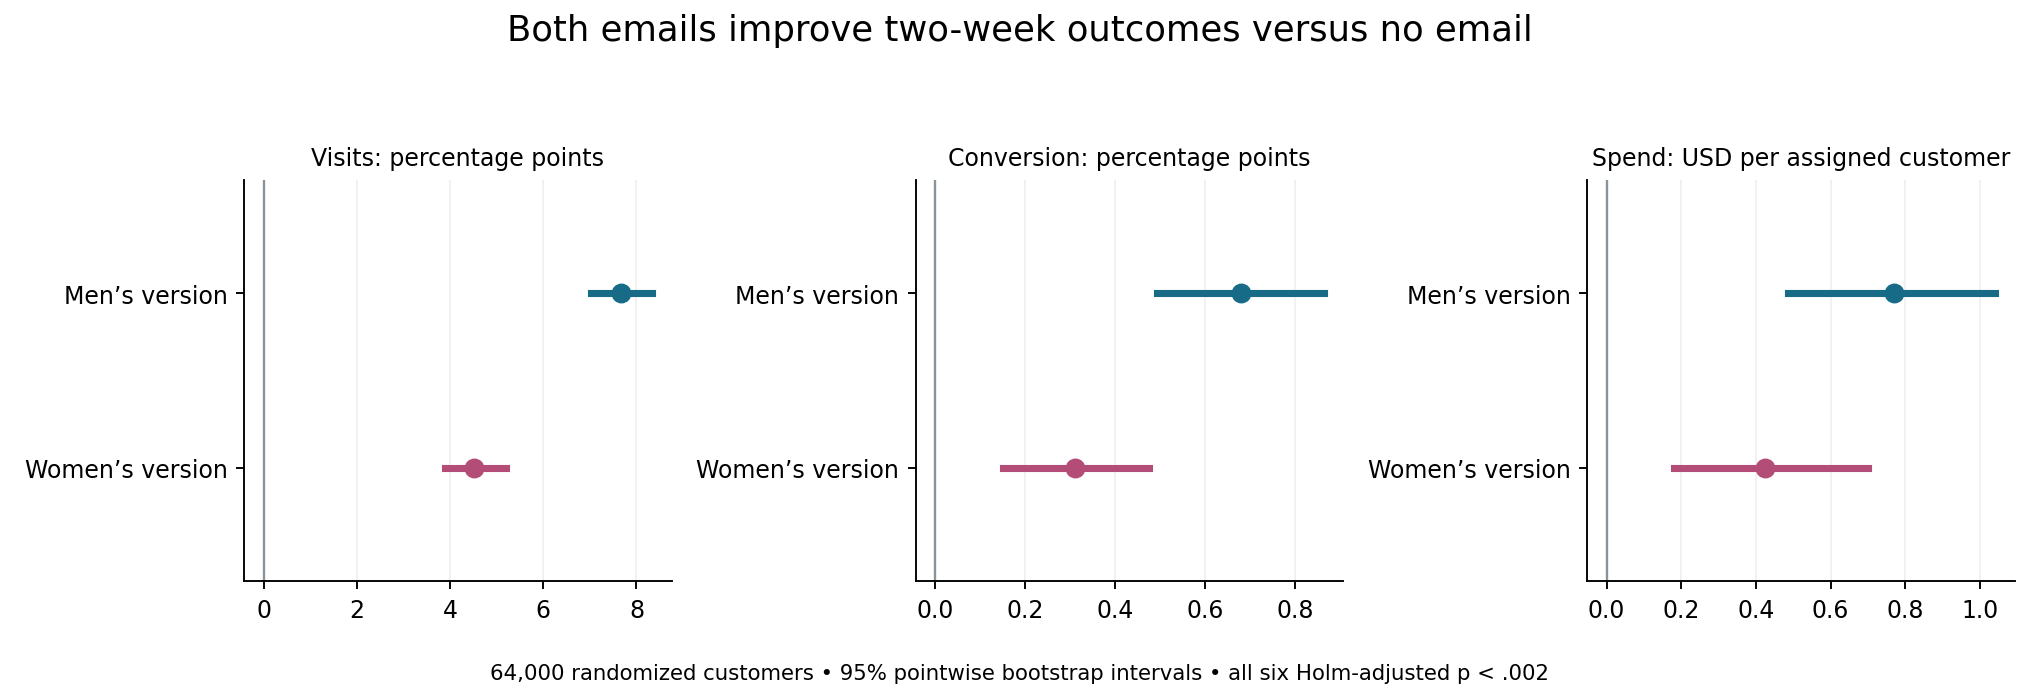

In [2]:
display(load('hillstrom_effects'))
display(load('email_head_to_head'))
display(Image(filename=str(ROOT/'charts/hillstrom_effects.png')))

## 2. Explore baseline customer cuts

Six cuts produce 126 exploratory comparisons with one Holm family. Merchandise purchase history does not identify customer sex or gender. A different significance label across two subgroups is not evidence of an interaction. Segment spending is sparse and noisy.

,cut,level,arm,metric,n_treatment,n_control,status,treatment_mean,control_mean,estimate,ci_low,ci_high,p_value,p_holm,reject_zero_holm_05
0,buyer,both,Mens E-Mail,visit,2181,2149,estimated,0.314993,0.180549,0.134444,0.109916,0.160119,6.294332e-25,6.986709e-23,True
3,buyer,both,Womens E-Mail,visit,2118,2149,estimated,0.251653,0.180549,0.071103,0.046248,0.095081,1.618484e-08,1.521375e-06,True
6,buyer,mens only,Mens E-Mail,visit,9558,9638,estimated,0.168968,0.099813,0.069155,0.059017,0.078845,5.564704e-45,6.566350e-43,True
9,buyer,mens only,Womens E-Mail,visit,9622,9638,estimated,0.110892,0.099813,0.011078,0.002875,0.020215,1.228106e-02,5.280858e-01,False
12,buyer,womens only,Mens E-Mail,visit,9568,9519,estimated,0.166388,0.095808,0.070580,0.060831,0.079803,1.474386e-47,1.769263e-45,True
15,buyer,womens only,Womens E-Mail,visit,9647,9519,estimated,0.169794,0.095808,0.073985,0.064738,0.083528,8.224101e-52,1.011564e-49,True


Exploratory tests: 126 | Cuts: buyer, newbie, channel, zip_code, history_segment, recency_band


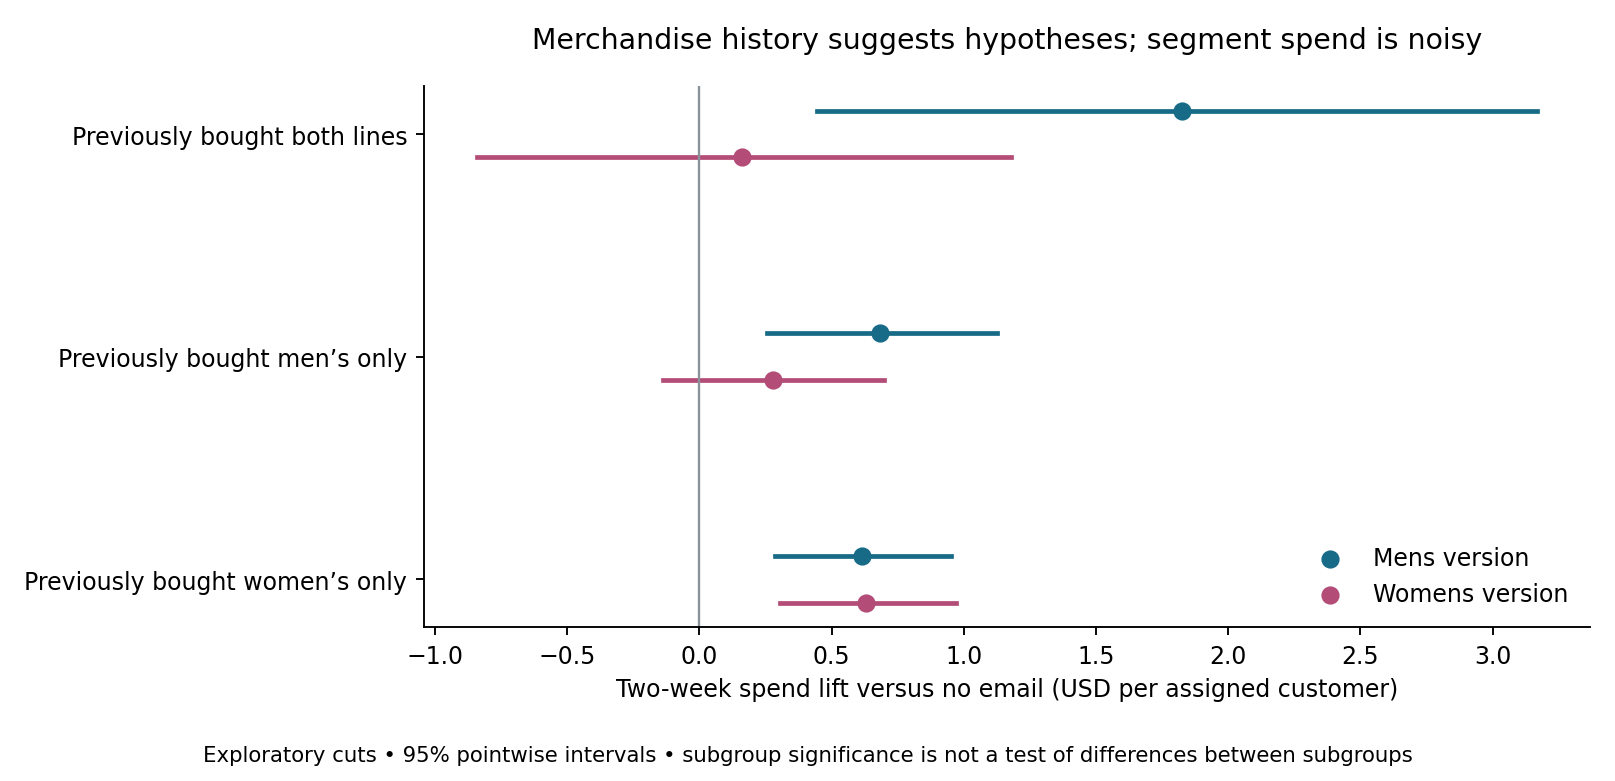

In [3]:
segments=load('segment_effects')
display(segments[(segments['cut']=='buyer') & (segments['metric']=='visit')])
print('Exploratory tests:',len(segments),'| Cuts:',', '.join(segments['cut'].unique()))
display(Image(filename=str(ROOT/'charts/hillstrom_buyer_segments.png')))

## 3. Freeze targeting before looking at validation outcomes

Thirty observed cells out of 36 possible; the six both-lines/low-spend cells are empty. Random half seed 7 trains the better-version spend score per cell. Outcomes or assignments from the held-out half cannot choose rules. Whole cells select 8,486, so outcome-free seeded boundary ties fill the exact 10,000 quota. Suppression is a forced capacity ranking, not evidence of harmful email.

,seed,scope,audience,population_customers,heldout_customers
0,7,exact,target,10000,5080
1,7,exact,suppress,10000,5061
2,7,exact,other,44000,22053
3,7,guide_whole_cells,target,8486,4273
4,7,guide_whole_cells,suppress,9420,4771
5,7,guide_whole_cells,not_targeted,55514,27921
6,8,exact,target,10000,4981
7,8,exact,suppress,10000,5025
8,8,exact,other,44000,22045
9,8,guide_whole_cells,target,9620,4792


,cell,train_control_mean,train_mens_mean,train_womens_mean,train_mens_lift,train_womens_lift,recommended_email,train_best_lift,population_customers,train_n_control,train_n_mens,train_n_womens,target_whole_cell,suppress_whole_cell,exact_target,exact_suppress,seed
0,both|0|1-3|high,0.000000,7.276842,0.668820,7.276842,0.668820,Mens E-Mail,7.276842,993,154,171,161,True,False,993,0,7
1,both|1|1-3|high,0.191086,2.033344,3.400464,1.842258,3.209378,Womens E-Mail,3.209378,2040,350,323,345,True,False,2040,0,7
2,womens only|1|1-3|high,0.201709,3.037347,1.565022,2.835639,1.363313,Mens E-Mail,2.835639,2447,398,377,458,True,False,2447,0,7
3,womens only|0|9-12|high,0.000000,2.256384,2.370165,2.256384,2.370165,Womens E-Mail,2.370165,1404,205,224,243,True,False,1404,0,7
4,mens only|1|4-8|high,0.538333,1.320338,2.797482,0.782005,2.259148,Womens E-Mail,2.259148,1602,264,266,274,True,False,1602,0,7
5,mens only|0|1-3|low,0.239002,2.041196,2.098310,1.802194,1.859307,Womens E-Mail,1.859307,2631,441,418,420,False,False,1514,0,7


,seed,scope,audience,arm,metric,n_treatment,n_control,status,treatment_mean,control_mean,estimate,ci_low,ci_high,p_value,p_holm,reject_zero_holm_05
2,7,exact,target,Mens E-Mail,spend,1718,1687,estimated,2.290646,0.669710,1.620937,0.555905,2.754037,0.003841,0.161342,False
8,7,exact,suppress,Mens E-Mail,spend,1682,1689,estimated,1.268579,0.583890,0.684689,-0.145427,1.654466,0.133299,1.000000,False
14,7,exact,other,Mens E-Mail,spend,7402,7353,estimated,1.323939,0.663690,0.660250,0.225316,1.146835,0.007761,0.279398,False
38,8,exact,target,Mens E-Mail,spend,1670,1651,estimated,1.792527,1.063101,0.729426,-0.492109,1.917180,0.247801,1.000000,False
44,8,exact,suppress,Mens E-Mail,spend,1676,1675,estimated,1.387894,0.842704,0.545189,-0.512432,1.635576,0.317473,1.000000,False
50,8,exact,other,Mens E-Mail,spend,7443,7338,estimated,1.217708,0.544715,0.672993,0.265800,1.086335,0.001796,0.079020,False


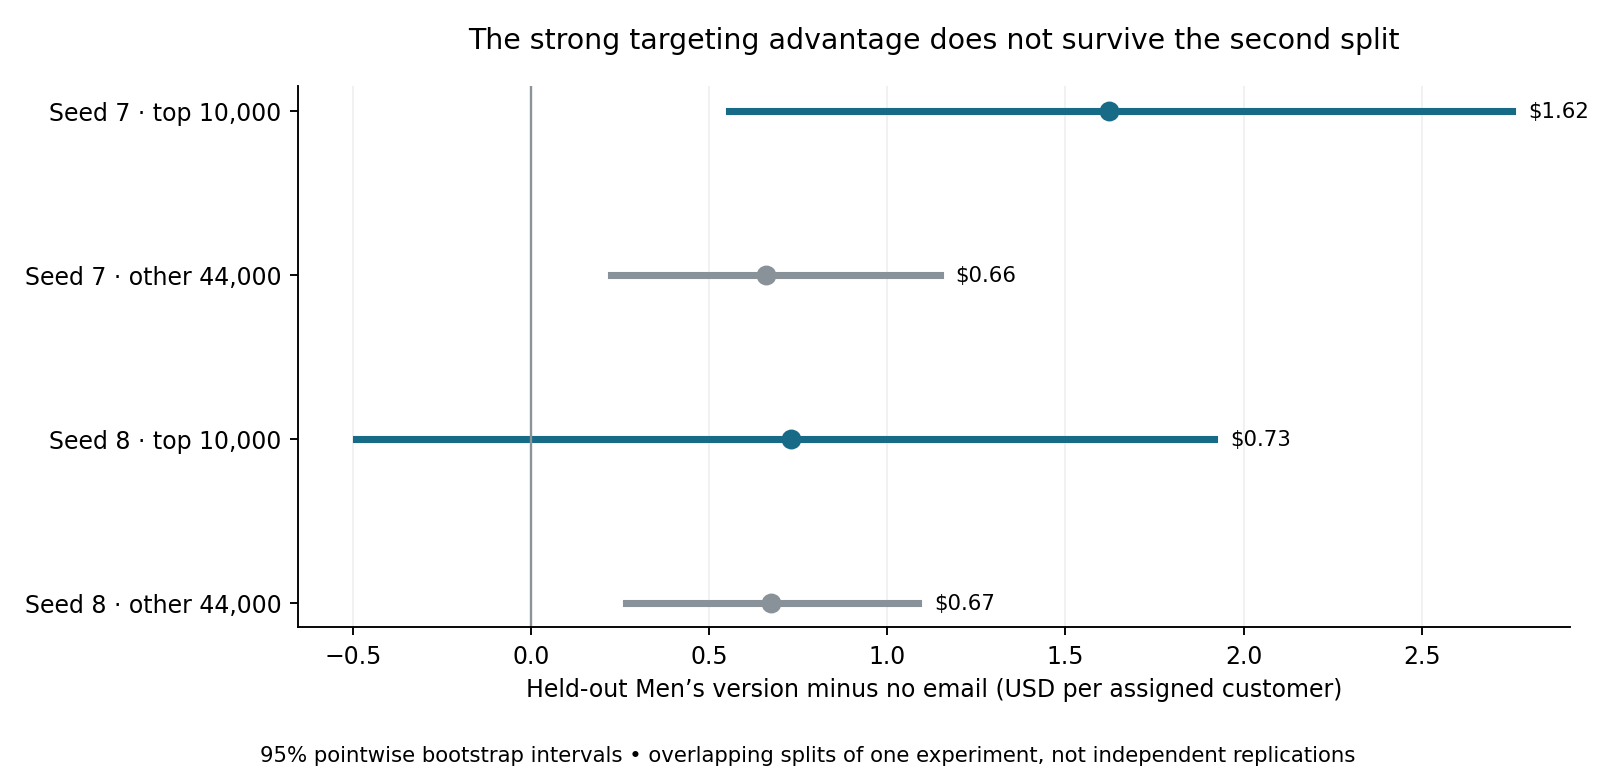

In [4]:
rules=load('policy_rules')
display(load('policy_audience_counts'))
display(rules[(rules['seed']==7)&(rules['exact_target']>0)])
heldout=load('heldout_effects')
display(heldout[(heldout['scope']=='exact')&(heldout['metric']=='spend')&(heldout['arm']=='Mens E-Mail')])
display(Image(filename=str(ROOT/'charts/hillstrom_targeting_validation.png')))

## 4. Evaluate the policy, not just one arm in its audience

The learned per-cell version policy needs its own value estimate. The Horvitz–Thompson estimator uses the known 1/3 randomized assignment probability and a paired comparison against always sending Men's. Validation intervals condition on the trained rule. Seed 8 is an overlapping sensitivity split, not a new experiment: it fails to confirm a strong targeting gain. Do not tune the policy using these validation results.

In [5]:
value=load('heldout_policy_value')
display(value[(value['metric']=='spend')&(value['audience']=='target')])
for decision in ['target','suppress']:
    candidates=load(decision+'_10000')
    assert len(candidates)==10000 and candidates['source_row'].is_unique
    print(decision, len(candidates), '| version suggestion status:',candidates['variant_suggestion_status'].unique())
display(load('hillstrom_profile'))
checks=load('hillstrom_checks')
assert checks['passed'].astype(str).str.lower().eq('true').all()
print(len(checks),'database checks passed')
display(checks)

,seed,audience,metric,heldout_customers,estimate,ci_low,ci_high,always_mens_estimate,policy_minus_mens,policy_minus_mens_ci_low,policy_minus_mens_ci_high
2,7,target,spend,5080,0.918549,-0.001520,1.937874,1.656809,-0.73826,-1.843509,0.368051
11,8,target,spend,4981,0.745838,-0.476014,1.981705,0.745838,0.00000,0.000000,0.000000


target 10000 | version suggestion status: ['training_only_not_validated']
suppress 10000 | version suggestion status: ['training_only_not_validated']


,customers,positive_spenders,zero_spenders,maximum_spend,total_spend,pre_treatment_cells,original_surburban_label_rows
0,64000,578,63422,499.0,67258.13,30,28776


27 database checks passed


,check_name,passed
0,64000_source_rows,True
1,source_row_unique,True
2,source_fields_non_null,True
3,three_expected_arms,True
4,binary_flags_valid,True
5,recency_valid,True
6,history_spend_finite_nonnegative,True
7,conversion_requires_visit,True
8,positive_spend_matches_conversion,True
9,observed_feature_cells_valid,True


## 5. Make a decision and learn the SQL workflow

Men's is supported as the population default; the selected cell version mix and ranking remain provisional. No email cost or margin is supplied, so do not claim net profit. To inspect the results in SQL, open `grocery_hillstrom.duckdb` in any SQL client and run `sql/06_hillstrom_learning.sql` one query at a time. The readout below answers eight questions about the experiment.

In [6]:
display(Markdown((ROOT/'docs/experiment_readout.md').read_text(encoding='utf-8')))